In [1]:
!python -m venv .venv
!source myenv/bin/activate
!python -m ipykernel install --user --name=myenv --display-name "Python (myenv)"
!pip install numpy pandas matplotlib 


zsh:source:1: no such file or directory: myenv/bin/activate
Installed kernelspec myenv in /Users/muhsilnr/Library/Jupyter/kernels/myenv


![Alt text](nnad.png)


In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [3]:
data = pd.read_csv('train.csv')

In [4]:
data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
data = np.array(data)
#m represents the number of images
#n reperesets the number of pixels
m,n = data.shape
#We randomize the data order because if the dataset
#in an order it affect the model perfomance
np.random.shuffle(data)

1. m is the total number of examples or image
2. n is the total number of (pixels/values) in an (example/image)

In [6]:
print(m,n)

42000 785


### Split the Data into two parts int Ration of 8:2
1. 80% for training
2. 20% for valuation

In [7]:
#Splitting the data into 80 percentage for training
train_data = data[0:int(0.8*m),:]
#Remaining data after splition 80 percentage for valuation
val_data= data[int(0.8*m):m, :]

### Now we split the data of training and valuation into 

1. Label (Y) 
2. Value (X)

#### The goal is tho map f(X) --> Y

In [8]:
#Actual data of images for training
#We want each column as the each image instead of each rows
#so we take transpose
X_train = train_data[:,1:].T 
#Convert the 0-255 pixel values scale down to 0 to 1 value
X_train = X_train/255.0
Y_train = train_data[:,0]
#Actual data of images for valuation
#first element in a row is label so we exclude the label slicing start form 1
#We want each column as the each image instead of each rows
#so we take transpose
X_val = val_data[:,1:].T
#Convert the 0-255 pixel values scale down to 0 to 1 value
X_val=X_val/255.0
Y_val = val_data[:,0]

In [9]:
print(X_val.shape)
print(Y_val.shape)
print(X_train.shape)
print(Y_train.shape)

(784, 8400)
(8400,)
(784, 33600)
(33600,)


Start with intializing the parameters

In [10]:
def intialize_parameters():
    W1 = np.random.rand(10, 784) - 0.5
    B1 = np.random.rand(10, 1) - 0.5
    W2 = np.random.rand(10, 10) - 0.5
    B2 = np.random.rand(10, 1) - 0.5
    return W1, B1, W2, B2
W1, B1, W2, B2 = intialize_parameters()
print(W1)


[[-0.43026828  0.12691094 -0.10659125 ... -0.0383023   0.29483588
   0.41730146]
 [ 0.42741505 -0.34898944  0.2516939  ...  0.14427426 -0.36894231
   0.01636245]
 [-0.43577978  0.1553766   0.38017262 ... -0.302297    0.24864238
  -0.41077824]
 ...
 [ 0.36675236 -0.17287964 -0.05493806 ... -0.31671909 -0.14606447
   0.41855011]
 [ 0.3335596   0.36907468 -0.25319727 ...  0.08584581  0.4895506
  -0.05135655]
 [ 0.24746404 -0.23845301  0.29624397 ...  0.31846444  0.07390949
  -0.00148481]]


#### Forward Propagation

In [11]:
def ReLU(X):
    return np.maximum(X,0)

def softmax_calculator(Z):
    return np.exp(Z) / sum(np.exp(Z))

def forward_propagation(W1, B1, W2, B2, X):
    Z1 = W1.dot(X) + B1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + B2
    A2 = softmax_calculator(Z2)
    return Z1, A1, Z2, A2

#### Backward Propagation

In [12]:
def one_hot_converter(Y):
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    return one_hot_Y.T

def backward_propagation(W1, B1, W2, B2, Z1, A1, Z2, A2, X, Y):
    one_hot_Y = one_hot_converter(Y)
    dZ2 = A2 - one_hot_Y
    dW2 = 1 / m * dZ2.dot(A1.T)
    dB2 = 1 / m * np.sum(dZ2)
    dZ1 = W2.T.dot(dZ2) * (Z1 > 0)
    dW1 = 1 / m * dZ1.dot(X.T)
    dB1 = 1 / m * np.sum(dZ1)
    return dW1, dB1, dW2, dB2

#### update Parameters

In [13]:
def update_parameters(W1,B1,W2,B2,dW1,dB1,dW2, dB2, learning_rate):
    W1 = W1 - learning_rate * dW1
    B1 = B1 - learning_rate * dB1
    W2 = W2 - learning_rate * dW2
    B2 = B2 - learning_rate * dB2
    return W1, B1, W2, B2

#### Get Prediction from last layer A2

In [14]:
def get_prediction(A2):
    return np.argmax(A2,0)

#### Get Accuracy

In [15]:
def get_accuracy(predictions, Y):
    return np.sum(predictions==Y)/Y.size 

#### Gradient descent

In [16]:
def gradient_descent(X,Y,alpha, iteration):
    W1, B1, W2, B2 = intialize_parameters()
    for i in range(iteration):
        Z1, A1, Z2, A2 = forward_propagation(W1, B1, W2, B2, X)
        dW1, dB1, dW2, dB2 = backward_propagation(W1, B1, W2, B2, Z1, A1, Z2, A2, X, Y)
        W1, B1, W2, B2 = update_parameters(W1, B1, W2, B2, dW1, dB1, dW2, dB2, alpha)
        if (i%10)==0:
            print("Iteration number: ",i)
            print(f"Accuracy: {get_accuracy(get_prediction(A2),Y)*100}%")

    return W1, B1, W2, B2

In [17]:
W1, B1, W2, B2 = gradient_descent(X_train, Y_train, 0.01, 12500 )

Iteration number:  0
Accuracy: 9.68452380952381%
Iteration number:  10
Accuracy: 9.535714285714286%
Iteration number:  20
Accuracy: 9.714285714285714%
Iteration number:  30
Accuracy: 10.61904761904762%
Iteration number:  40
Accuracy: 11.880952380952381%
Iteration number:  50
Accuracy: 13.520833333333334%
Iteration number:  60
Accuracy: 14.869047619047619%
Iteration number:  70
Accuracy: 16.220238095238095%
Iteration number:  80
Accuracy: 17.383928571428573%
Iteration number:  90
Accuracy: 18.544642857142858%
Iteration number:  100
Accuracy: 19.761904761904763%
Iteration number:  110
Accuracy: 20.80654761904762%
Iteration number:  120
Accuracy: 21.776785714285715%
Iteration number:  130
Accuracy: 22.699404761904763%
Iteration number:  140
Accuracy: 23.598214285714285%
Iteration number:  150
Accuracy: 24.401785714285715%
Iteration number:  160
Accuracy: 25.11309523809524%
Iteration number:  170
Accuracy: 25.982142857142858%
Iteration number:  180
Accuracy: 26.729166666666664%
Iteration n

Predicted Label:  [2]
Actual label:  2


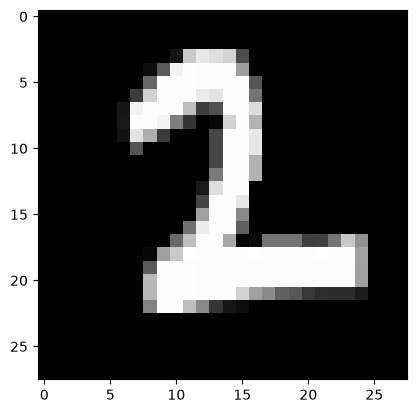

In [18]:
val_index=70
Z1val, A1val, Z2val, A2val = forward_propagation(W1, B1,W2, B2, X_val[:,val_index,None])
print("Predicted Label: ",get_prediction(A2val))
print("Actual label: ",Y_val[val_index])

image_array = X_val[:,val_index].reshape(28,28)
plt.imshow(image_array,cmap='gray')
plt.show()

In [19]:
Z1val, A1val, Z2val, A2val = forward_propagation(W1, B1,W2, B2, X_val)
val_acc=get_accuracy(get_prediction(A2val), Y_val)
print(f"Validation accuracy = {val_acc*100}%")

Validation accuracy = 87.51190476190476%
